In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df_daily   = pd.read_parquet("era5europa_daily.parquet")
df_monthly = pd.read_parquet("era5europa_monthly.parquet")
df_yearly  = pd.read_parquet("era5europa_yearly.parquet")

KEY = ["kraj", "miasto"]
print(df_yearly.shape, df_monthly.shape, df_daily.shape)

(3132, 20) (37260, 23) (1133892, 19)


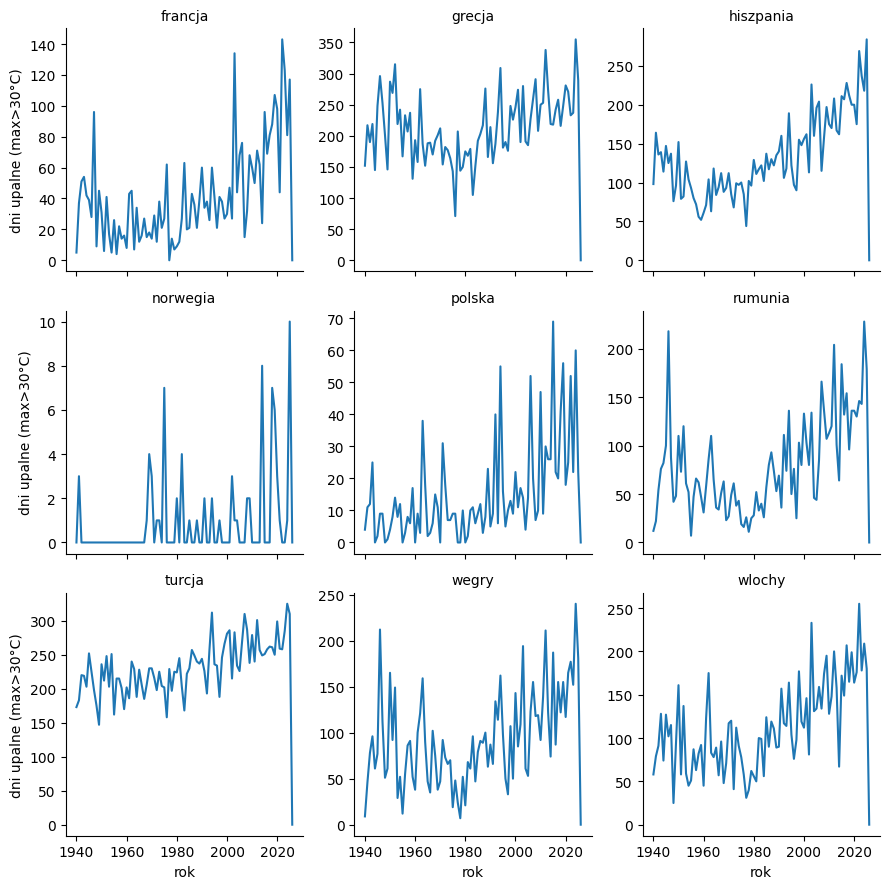

In [3]:
heat_trend = (
    df_yearly.groupby(["kraj", "year"])["hot_days_annual"]
    .sum()
    .reset_index()
)
g = sns.FacetGrid(heat_trend, col="kraj", col_wrap=3, height=3, sharey=False)
g.map_dataframe(sns.lineplot, x="year", y="hot_days_annual")
g.set_titles("{col_name}")
g.set_axis_labels("rok", "dni upalne (max>30°C)")
plt.tight_layout(); plt.show()

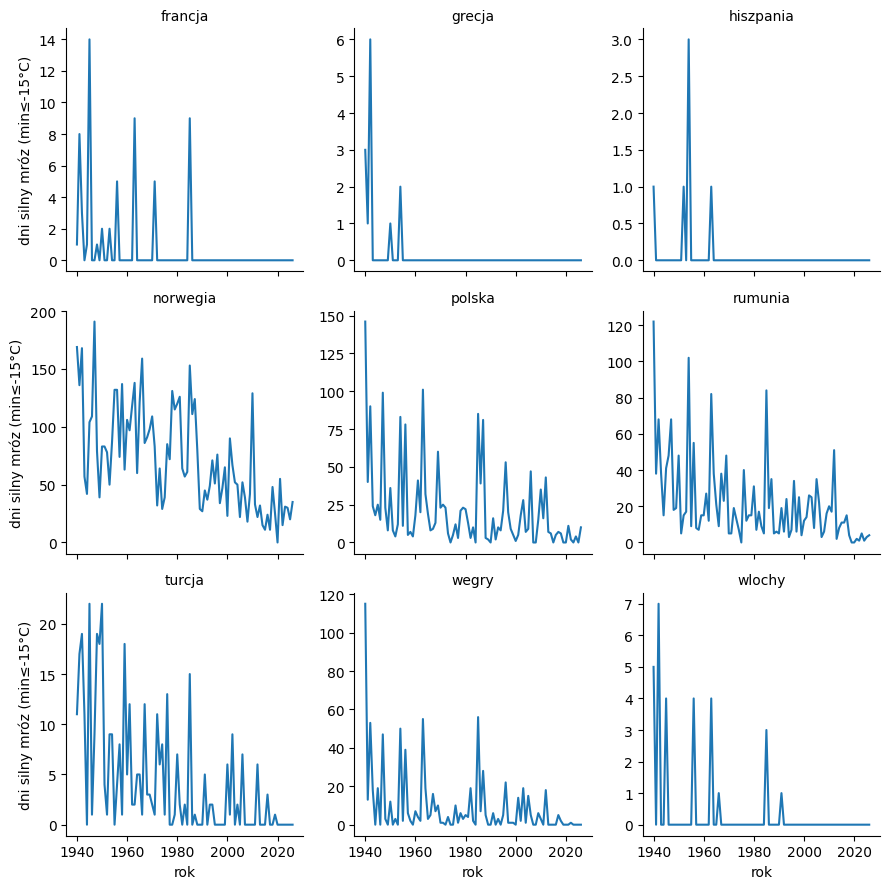

In [4]:
frost_trend = (
    df_yearly.groupby(["kraj", "year"])["cold_days_annual"]
    .sum()
    .reset_index()
)
g = sns.FacetGrid(frost_trend, col="kraj", col_wrap=3, height=3, sharey=False)
g.map_dataframe(sns.lineplot, x="year", y="cold_days_annual")
g.set_titles("{col_name}")
g.set_axis_labels("rok", "dni silny mróz (min≤-15°C)")
plt.tight_layout(); plt.show()

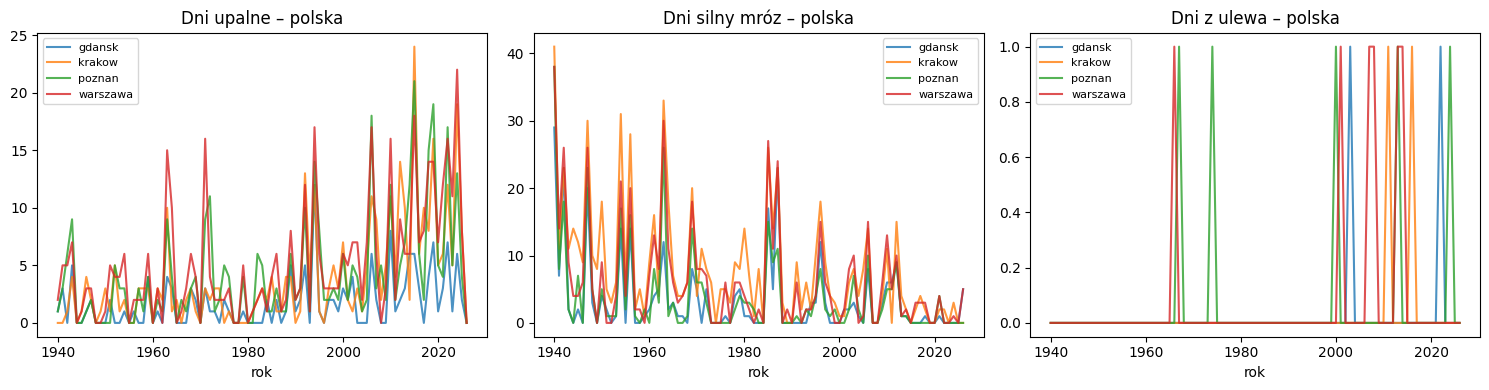

In [5]:

KRAJ = "polska"

subset = df_yearly[df_yearly["kraj"] == KRAJ]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, title in zip(axes,
    ["hot_days_annual", "cold_days_annual", "heavy_rain_days_annual"],
    ["Dni upalne", "Dni silny mróz", "Dni z ulewa"]):
    for miasto, grp in subset.groupby("miasto"):
        ax.plot(grp["year"], grp[col], label=miasto, alpha=0.8)
    ax.set_title(f"{title} – {KRAJ}")
    ax.set_xlabel("rok"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

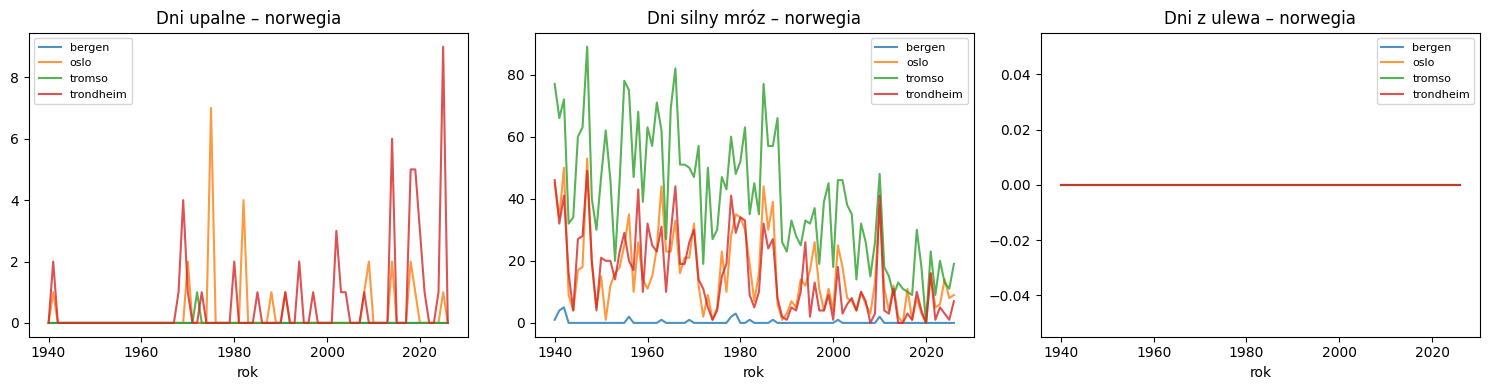

In [6]:
KRAJ = "norwegia"

subset = df_yearly[df_yearly["kraj"] == KRAJ]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, title in zip(axes,
    ["hot_days_annual", "cold_days_annual", "heavy_rain_days_annual"],
    ["Dni upalne", "Dni silny mróz", "Dni z ulewa"]):
    for miasto, grp in subset.groupby("miasto"):
        ax.plot(grp["year"], grp[col], label=miasto, alpha=0.8)
    ax.set_title(f"{title} – {KRAJ}")
    ax.set_xlabel("rok"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

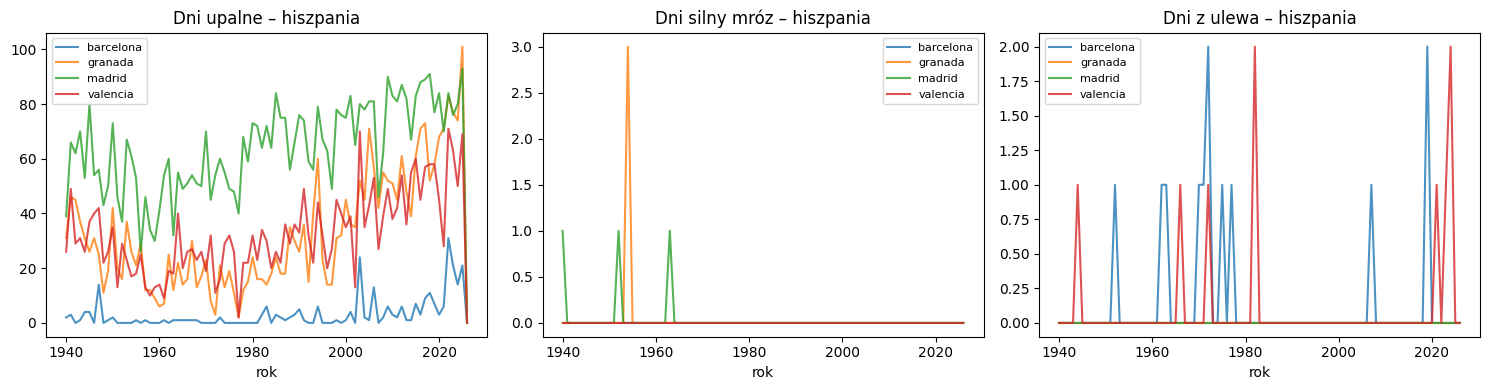

In [7]:
KRAJ = "hiszpania"

subset = df_yearly[df_yearly["kraj"] == KRAJ]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, title in zip(axes,
    ["hot_days_annual", "cold_days_annual", "heavy_rain_days_annual"],
    ["Dni upalne", "Dni silny mróz", "Dni z ulewa"]):
    for miasto, grp in subset.groupby("miasto"):
        ax.plot(grp["year"], grp[col], label=miasto, alpha=0.8)
    ax.set_title(f"{title} – {KRAJ}")
    ax.set_xlabel("rok"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

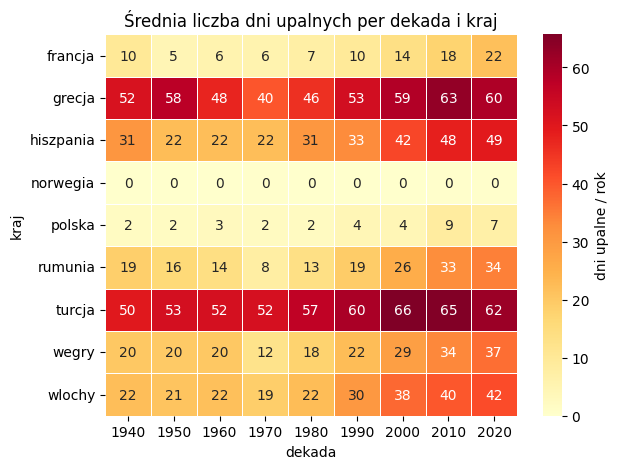

In [8]:

df_yearly["dekada"] = (df_yearly["year"] // 10) * 10

heat_dek = (
    df_yearly.groupby(["kraj", "dekada"])["hot_days_annual"]
    .mean()
    .unstack("dekada")
    .round(1)
)
sns.heatmap(heat_dek, annot=True, fmt=".0f", cmap="YlOrRd",
            linewidths=0.5, cbar_kws={"label": "dni upalne / rok"})
plt.title("Średnia liczba dni upalnych per dekada i kraj")
plt.tight_layout(); plt.show()

In [9]:
df_yearly.columns

Index(['year', 'tempC_mean', 'tempC_min', 'tempC_max', 'dewpointC_mean',
       'humidity_mean', 'tempdewdiff_mean', 'windspeed_mean', 'windspeed_max',
       'tpmm_annual', 'tpmm_extreme_annual', 'extreme_hours_annual',
       'rainy_days_annual', 'heavy_rain_days_annual', 'heat_hours_annual',
       'frost_hours_annual', 'hot_days_annual', 'cold_days_annual', 'kraj',
       'miasto', 'dekada'],
      dtype='object')

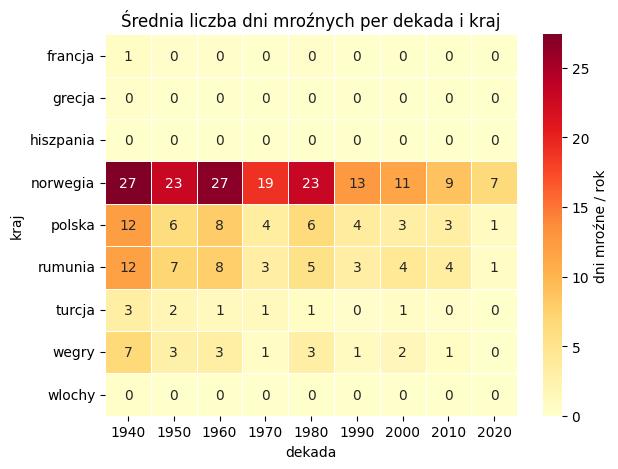

In [10]:

heat_dek = (
    df_yearly.groupby(["kraj", "dekada"])["cold_days_annual"]
    .mean()
    .unstack("dekada")
    .round(1)
)
sns.heatmap(heat_dek, annot=True, fmt=".0f", cmap="YlOrRd",
            linewidths=0.5, cbar_kws={"label": "dni mroźne / rok"})
plt.title("Średnia liczba dni mroźnych per dekada i kraj")
plt.tight_layout(); plt.show()

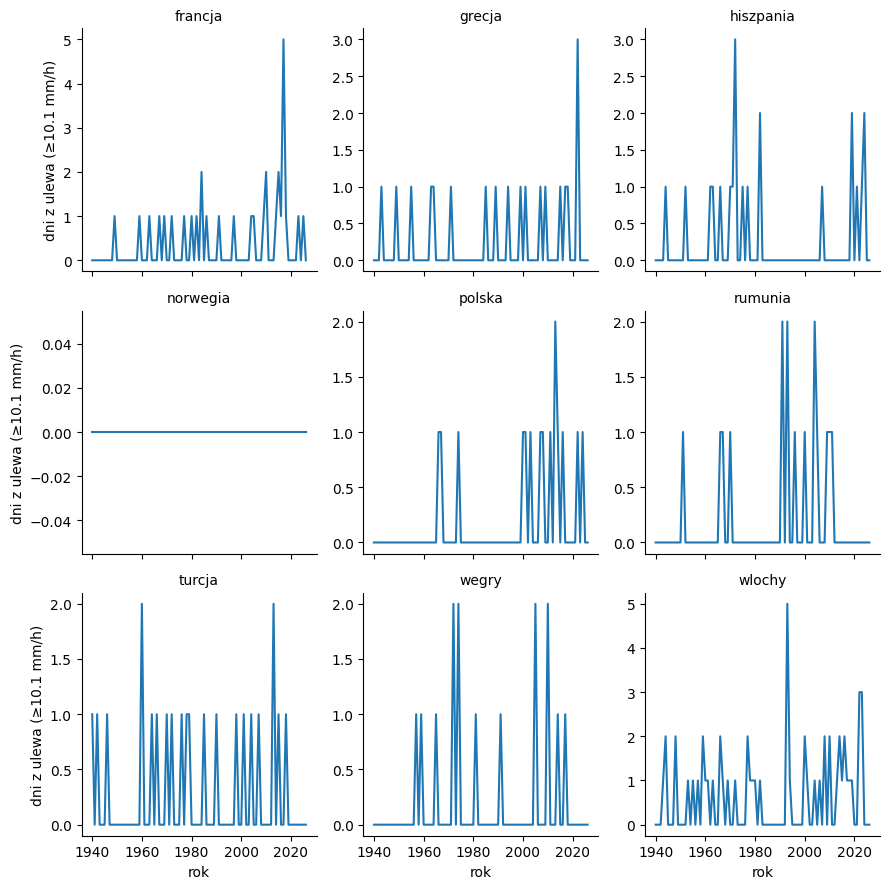

In [11]:
ulewa_trend = (
    df_yearly.groupby(["kraj", "year"])["heavy_rain_days_annual"]
    .sum()
    .reset_index()
)
g = sns.FacetGrid(ulewa_trend, col="kraj", col_wrap=3, height=3, sharey=False)
g.map_dataframe(sns.lineplot, x="year", y="heavy_rain_days_annual")
g.set_titles("{col_name}")
g.set_axis_labels("rok", "dni z ulewa (≥10.1 mm/h)")
plt.tight_layout(); plt.show()

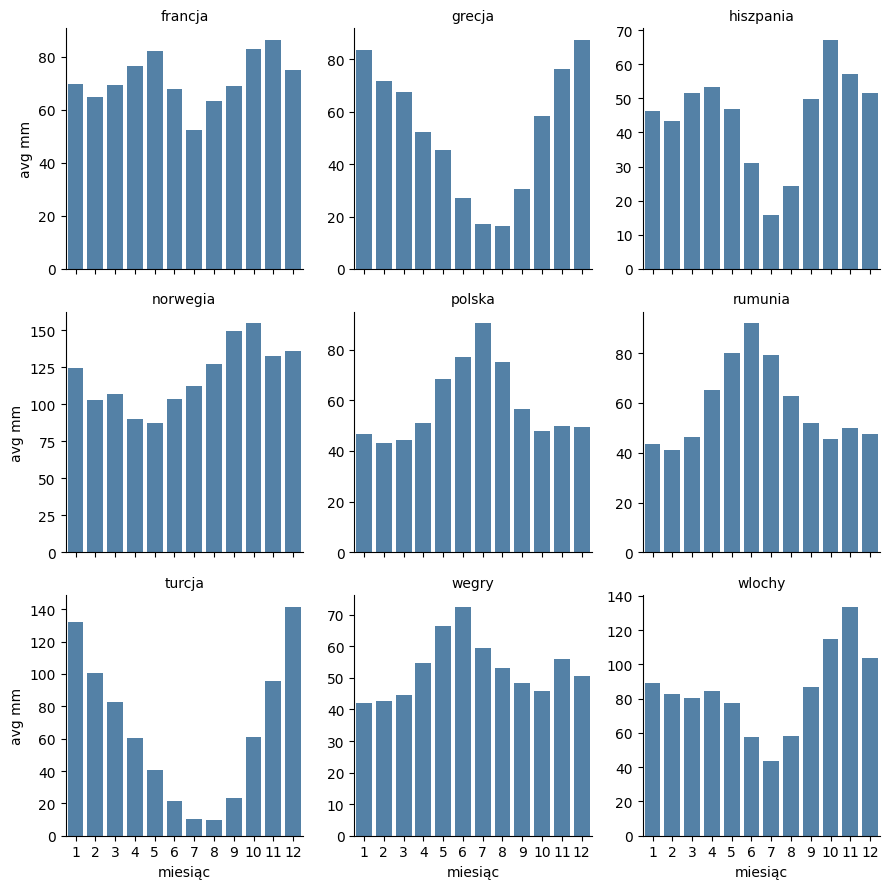

In [12]:
# średnia suma opadów per miesiąc per kraj
rain_season = (
    df_monthly.groupby(["kraj", "month"])["tpmm_sum"]
    .mean()
    .reset_index()
)
g = sns.FacetGrid(rain_season, col="kraj", col_wrap=3, height=3, sharey=False)
g.map_dataframe(sns.barplot, x="month", y="tpmm_sum", color="steelblue")
g.set_titles("{col_name}")
g.set_axis_labels("miesiąc", "avg mm")
plt.tight_layout(); plt.show()

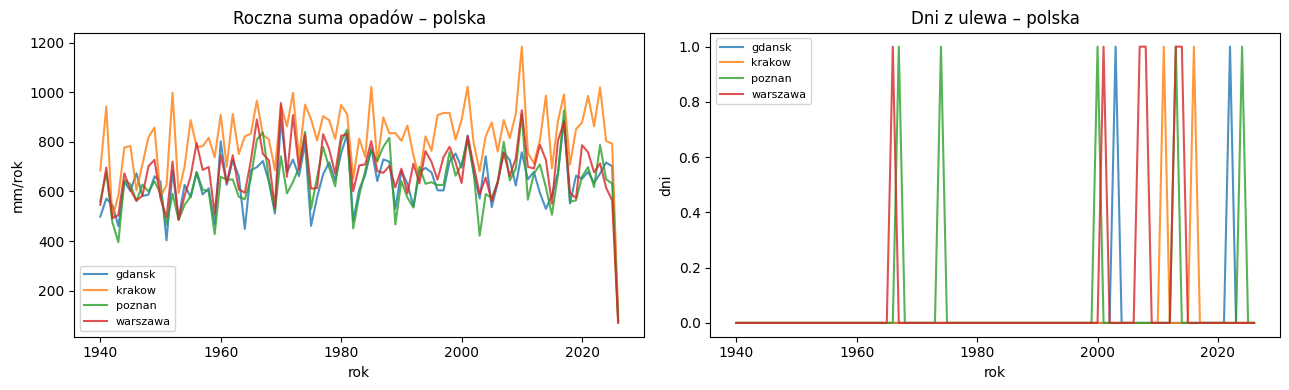

In [13]:
KRAJ = "polska" 

subset = df_yearly[df_yearly["kraj"] == KRAJ]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for miasto, grp in subset.groupby("miasto"):
    axes[0].plot(grp["year"], grp["tpmm_annual"], label=miasto, alpha=0.8)
axes[0].set_title(f"Roczna suma opadów – {KRAJ}")
axes[0].set_xlabel("rok"); axes[0].set_ylabel("mm/rok"); axes[0].legend(fontsize=8)

for miasto, grp in subset.groupby("miasto"):
    axes[1].plot(grp["year"], grp["heavy_rain_days_annual"], label=miasto, alpha=0.8)
axes[1].set_title(f"Dni z ulewa – {KRAJ}")
axes[1].set_xlabel("rok"); axes[1].set_ylabel("dni"); axes[1].legend(fontsize=8)

plt.tight_layout(); plt.show()

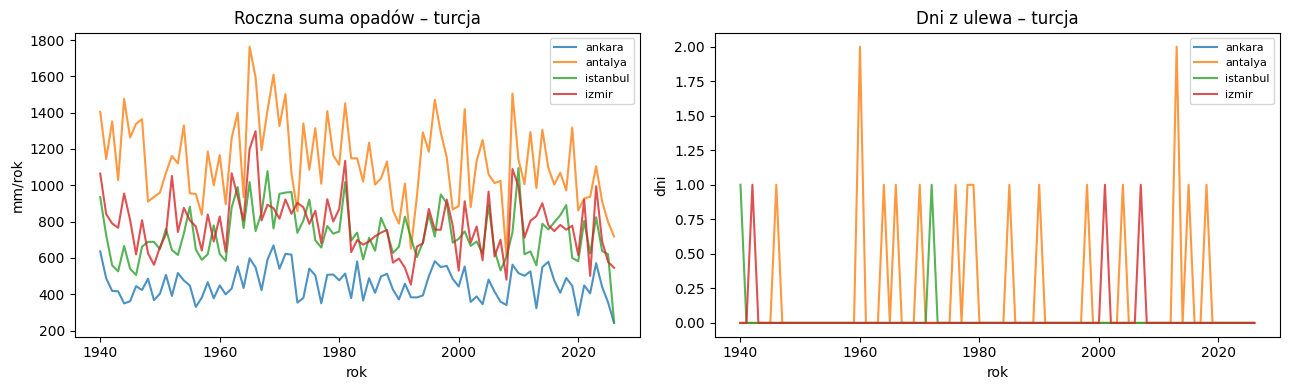

In [14]:
KRAJ = "turcja" 

subset = df_yearly[df_yearly["kraj"] == KRAJ]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for miasto, grp in subset.groupby("miasto"):
    axes[0].plot(grp["year"], grp["tpmm_annual"], label=miasto, alpha=0.8)
axes[0].set_title(f"Roczna suma opadów – {KRAJ}")
axes[0].set_xlabel("rok"); axes[0].set_ylabel("mm/rok"); axes[0].legend(fontsize=8)

for miasto, grp in subset.groupby("miasto"):
    axes[1].plot(grp["year"], grp["heavy_rain_days_annual"], label=miasto, alpha=0.8)
axes[1].set_title(f"Dni z ulewa – {KRAJ}")
axes[1].set_xlabel("rok"); axes[1].set_ylabel("dni"); axes[1].legend(fontsize=8)

plt.tight_layout(); plt.show()